# Data tới AI tới quyết định
Cell sau thực hiện một phiên kiểm thử chức năng tự động trên dữ liệu thật. Phản hồi do cell tạo là thao tác thử, không thay cho nghiệm thu của người dùng.

In [1]:
from pathlib import Path
import sys,json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/appliances').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.appliances.config import RELEASE,MODEL_DIR,HORIZONS,BOUNDARIES
from src.appliances.data import load_data
from src.appliances.features import supervised,split_rows,make_features,feature_columns
raw,audit=load_data()
rows,columns=supervised(raw)
parts,counts=split_rows(rows)
def read_json(name):
    return json.loads((RELEASE/name).read_text(encoding='utf-8'))


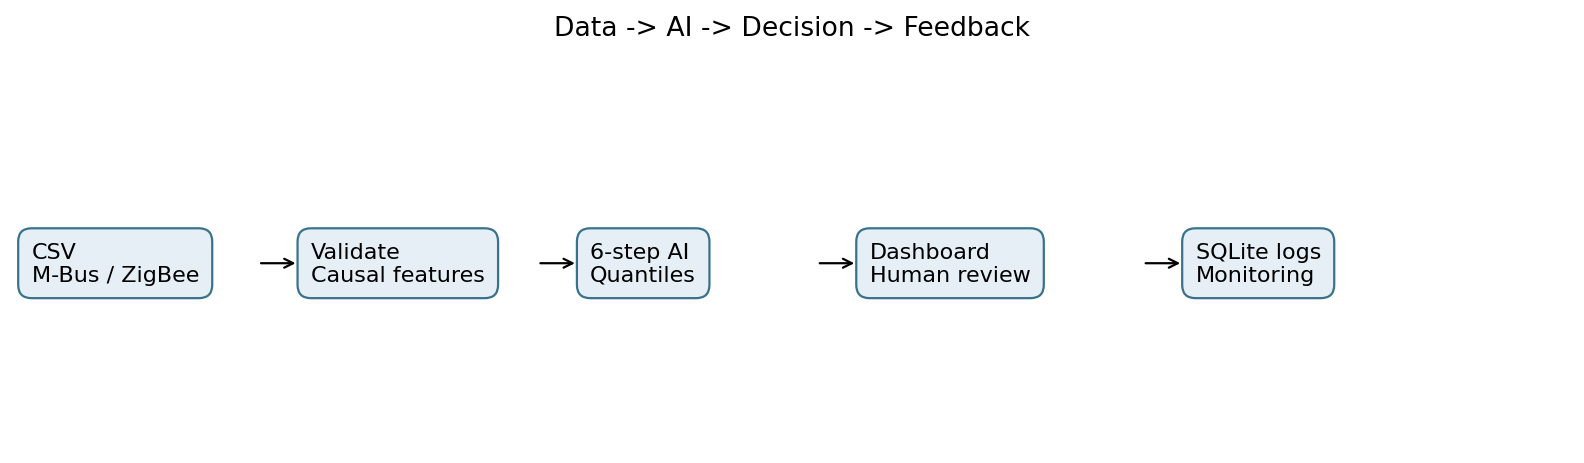

In [2]:
display(Image(filename=str(RELEASE/"figures/09_architecture.png")))

In [3]:
import tempfile
from src.appliances.demo import Replay
with tempfile.TemporaryDirectory() as directory:
    demo=Replay(Path(directory)/"session.sqlite3")
    try:
        first=demo.dispatch()
        print("Lúc phát dự báo, actual =",first["forecast"]["actual_hour_kWh"])
        for _ in range(18):
            state=demo.dispatch("step")
        display(pd.Series(state["monitoring"]))
        display(pd.DataFrame(state["forecast"]["horizons"]))
        state=demo.dispatch("decision",{"token":"notebook-functional-test","issue_time":state["forecast"]["issue_time"],"operator":"Automated notebook test","action":"inspect","note":"Functional test only"})
        display(pd.DataFrame(state["decisions"]))
        display(pd.read_sql_query("SELECT issue_time,actual,predicted FROM forecasts ORDER BY issue_time LIMIT 8",demo.db))
    finally:
        demo.db.close()

Lúc phát dự báo, actual = None


status                 insufficient_history
matured_forecasts                        13
required_for_review                     288
mae_hour_kWh                       0.028075
coverage                                1.0
dtype: object

,time,minutes,predicted_kWh
0,2016-05-09T03:10:00,10,0.050143
1,2016-05-09T03:20:00,20,0.049749
2,2016-05-09T03:30:00,30,0.047594
3,2016-05-09T03:40:00,40,0.049637
4,2016-05-09T03:50:00,50,0.053627
5,2016-05-09T04:00:00,60,0.052566


,issue_time,operator,action,note
0,2016-05-09T03:00:00,Automated notebook test,inspect,Functional test only


,issue_time,actual,predicted
0,2016-05-09T00:00:00,0.32,0.314098
1,2016-05-09T00:10:00,0.34,0.314935
2,2016-05-09T00:20:00,0.34,0.298951
3,2016-05-09T00:30:00,0.35,0.305584
4,2016-05-09T00:40:00,0.35,0.311223
5,2016-05-09T00:50:00,0.35,0.311916
6,2016-05-09T01:00:00,0.35,0.312027
7,2016-05-09T01:10:00,0.34,0.332501


## Chạy giao diện
Tại thư mục gốc chạy `python -X utf8 -m scripts.serve_demo --port 8767`, sau đó mở http://127.0.0.1:8767/. Nhật ký SQLite nằm ở outputs, độc lập với CSV gốc. Người dùng xem khoảng dự báo, cảnh báo và phản hồi. Hai cửa sổ ngày mới đủ cho quy tắc giám sát.

## Trước khi bảo vệ
Ba thành viên cần nghiệm thu trên máy trình bày và một máy khác, kiểm tra từng thao tác và giải thích những tình huống mô hình sai.